# Homework Assignment 3 - User-Defined Functions & Data Structures

### Total: 100 points

### Instructions:

1. **You need to submit the assignment as an HTML file**, which should be created from **File > Save and Export Notebook As > HTML** in the top menu. **(2 points)**


2. **Do not write your name anywhere on the assignment.** Assignments are graded anonymously. **(1 point)**


3. Write your code as clean and organized as possible:

- There should not be any excessively long outputs. (e.g. printing unnecessary results without good reason, printing something unnecessary inside a loop etc.) There should not be any piece of unnecessary code (running or commented out) or unnecessary text. **(1 point)**
- The code should be commented and clearly written with intuitive variable names. **(1 point)** Also keep in mind that **graders cannot give any partial credit to code they cannot follow.**

### 1)

In this question, you need to use the **count_word** function you wrote in the last question for Homework Assignment 2.

Write a program that asks the user to input a sentence and prints the word that occurs the most in the sentence and its number of occurrences. You do not need to check for invalid inputs.

Run your program with **“Sea shells are on the sea shore when the sea is calm.”** as the input sentence. The program should print **“The word with the maximum number of occurences is ‘sea’ and it occurs 3 times.”**

**Hints:**

1. If multiple words are tied for the maximum occurrence, you may choose to only print one of them.
2. Find a string method that can split a sentence into a **list** of words.
3. Note that you need to call the **count_word** function in your code.
4. Careful with upper case characters: note that the example output above has the word printed only in lower case ('sea').

**(12.5 points)**

In [ ]:
def count_word(word, sentence):
    return (sentence.lower()).count(word.lower())

word_counts = {}

sentence = input("Please input a sentence.")

sentence_list = sentence.split(" ")

for word in sentence_list:
    if word.lower() not in word_counts: # append word and # of occurences to word_counts dict if we haven't already added it
        word_counts[word.lower()] = count_word(word.lower(), sentence)

max_count = max(word_counts, key=word_counts.get) # get the word with the highest number of occurences; we don't care which word we choose if multiple are tied, so no need to go any further
print("The word with the maximum number of occurences is '{}' and it occurs {} times.".format(max_count, word_counts[max_count]))

The word with the maximum number of occurences is 'sea' and it occurs 3 times.


### 2)

This question will simulate a **random walk in two dimensions**. Imagine someone who has had too much to drink taking a walk in a neighborhood partitioned into blocks. Starting at the origin, the person chooses a random direction: north, west, east, or south with equal probability, and walks along that direction for one block. At the end of the block the person then chooses another random direction (which could be the reverse direction) with equal probability, walks for one block, then chooses another random direction, walks another block, and so forth. This type of random path approximates what is known as **Brownian motion**, and is used to model many physical processes, including the diffusion of smoke in the air, noise in electrical circuits, the firing of neurons in the brain, as well as the movement of prices in different types of markets.

**Assume that the random walk takes place on the x−y plane starting at the origin, and that each step has length one, and consists of moving up, down, left, or right with equal probability. Here is an example of a possible sequence of steps:**

                      (0, 0) → (−1, 0) → (0, 0) → (0, 1) → (1, 1) → (1, 2) → (1, 1) → (1, 2) → (0, 2)
                      
Note that any diagonal move is **not** allowed.

### a)

Write a **random_walk_generator** function that takes the total number of steps as the only input and returns the Euclidean distance from the origin at the end of the random walk as the only output. You do not need to check for invalid inputs. **(12.5 points)**

Call the function with 500 steps to check if it works.

**Hints:**

1. The walk starts from the origin, so properly initializing two variables that will represent the x and y coordinates is a good way to start.
2. For one step, pick a random integer between 1 and 4 (or in any range of four numbers) using the **randint** function from the **random** library. Use the possible values of this integer as the keys for the possible directions. Update the x and y coordinates accordingly.
2. You need to take the square root to calculate the **Euclidean distance** from the origin at the end. Use **np.sqrt**, the square root function of **Numpy**.

In [89]:
from random import randint
import numpy as np

def random_walk_generator(steps):
    current_coords = [0, 0] # use a list as we need mutability to update coordinates
    for i in range(steps):
        direction = randint(1, 4)

        if direction == 1: # go north
            current_coords[0] += 1
        elif direction == 2: # go south
            current_coords[0] -= 1
        elif direction == 3: # go east
            current_coords[1] += 1
        else: # go west
            current_coords[1] -= 1

    return float(np.sqrt(current_coords[0]**2 + current_coords[1]**2)) # calculate Euclidean distance from origin and convert from np float64 to python float

random_walk_generator(500)

17.029386365926403

### b)

Like most experiments/simulations with randomness involved, more reliable output can be obtained by running the function for multiple trials. Call the **random_walk_generator** function 10,000 times with 500 steps each time. Store all outputs in a list called **random_walk_distances**. **(5 points)**

Afterwards, run the given code to print the average distance over all trials and to plot a histogram that shows how the distance is distributed over the 10,000 random walk trials. (You do not need to change anything in the given code.)

In [90]:
random_walk_distances = []

for i in range(10000):
    random_walk_distances.append(random_walk_generator(500))

Average distance for 500 steps over 10,000 trials: 19.677598558894054


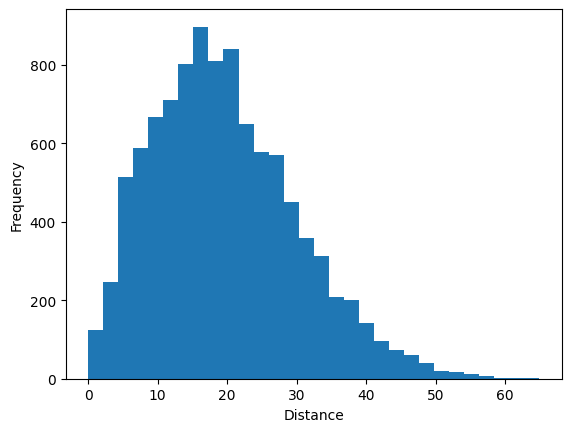

In [91]:
import matplotlib.pyplot as plt

print('Average distance for 500 steps over 10,000 trials:', np.mean(random_walk_distances))
plt.hist(random_walk_distances, bins=30)
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.show()

### 3)

The list below contains the GDP per capita of the United States for each year between 1960 and 2021, in ascending year order. (The first value is for 1960, the second value is for 1961, etc.)

In [71]:
gdp_list = [3007, 3067, 3244, 3375,3574, 3828, 4146, 4336, 4696, 5032,5234,5609,6094,6726,7226,7801,8592,9453,10565,11674,12575,13976,14434,15544,17121,18237,19071,20039,21417,22857,23889,24342,25419,26387,27695,28691,29968,31459,32854,34515,36330,37134,37998,39490,41725,44123,46302,48050,48570,47195,48651,50066,51784,53291,55124,56763,57867,59915,62805,65095,63028,69288]

### a)

Create a list of the differences between consecutive years, which is the change in GDP per capita each year. Note that you will have one less element in this new list because the first value will be for 1961. **(8 points)**

You do not need to print anything for this part.

In [70]:
gdp_differences = []

for index, year in enumerate(gdp_list[1:]): # enumerate as we'll be using the index to grab the previous year as well; make sure the list we're iterating over has one less item
    gdp_differences.append(gdp_list[index+1]-gdp_list[index]) # index starts at 0 and will end at len(gdp_list)-2, meaning that the last difference will be (2021 GDP - 2020 GDP)

### b)

Use the list created in Part a to calculate and print the maximum increase in GDP per capita. **(5 points)**

In [72]:
max_increase = max(gdp_differences)
print(max_increase)

6260


### c)

Use the list created in Part a to calculate and print the percentage of changes that are greater than $1000. **(10 points)**

In [92]:
changes_greater_1000 = [change for change in gdp_differences if change > 1000] # generate a list of just the changes greater than $1000
proportion_greater_1000 = len(changes_greater_1000)/len(gdp_differences)
print(f"{proportion_greater_1000:.2%}") # print formatted as a % to two decimal places

52.46%


### d)

Using the list created in Part a, create a dictionary, where each value is the value in the list (the change in GDP per capita) and each key is the corresponding year. (Read Part a again as a reminder for which year to start with.) **(10 points)** 

You do not need to print anything for this part.

In [73]:
gdp_dict = {}

year = 1961
for diff in gdp_differences:
    gdp_dict[year] = diff
    year += 1

### e) 

Use the dictionary created in Part d to find and print the year with the maximum increase in GDP per capita. **(12 points)**

In [74]:
max_year = max(gdp_dict, key=gdp_dict.get) # get the word with the highest number of occurances
print(max_year)

2021


### f)

Use the dictionary created in Part d to find and print the years with a **decrease** in GDP per capita from the previous year. **(10 points)**

In [78]:
for year, change in gdp_dict.items():
    if change < 0:
        print(f'There was a decrease of {change} in GDP per capita in {year}')

There was a decrease of -1375 in GDP per capita in 2009
There was a decrease of -2067 in GDP per capita in 2020


### 4)

The code given below reads the **TED_Talks.json** file. For the code to work properly, **the json file should be in the same folder as this ipynb file**.

JSON is a type of data file that can be easily read in Python with a few lines of code. In this course, you do not need to know how the given code works; just run it to create a **TED_Talks_data** variable, in which the data in the json file is stored. In this question, you will briefly explore **TED_Talks_data** as a data structure. (You will work on it in more depth in Homework Assignment 4.)

In [79]:
import json
with open("TED_Talks.json", "r") as file:
    TED_Talks_data=json.load(file)

### a)

- What is the data type of **TED_Talks_data**? Print the type to answer this question.
- What does each element in **TED_Talks_data** represent? Print one element and briefly describe it to answer this question.
- What is the data type of each element in **TED_Talks_data**? Print the type to answer this question.

**(2x3 = 6 points)**

In [86]:
print(type(TED_Talks_data).__name__) # list as we are grabbing a JSON array; use __name__ to convert type name to a string
print(TED_Talks_data[0]) # represents one TED Talk with all associated info, including speaker, talk name and description, date information, event information, links to a video and transcript, and ratings
print(type(TED_Talks_data[0]).__name__) # dict as the array is full of JSON objects; use __name__ to convert type name to a string

list
{'id': 7, 'speaker': 'David Pogue', 'headline': 'Simplicity sells', 'URL': 'http://www.ted.com/talks/view/id/7', 'description': 'New York Times columnist David Pogue takes aim at technologyâ€™s worst interface-design offenders, and provides encouraging examples of products that get it right. To funny things up, he bursts into song.', 'transcript_URL': 'http://www.ted.com/talks/view/id/7/transcript?language=en', 'month_filmed': 2, 'year_filmed': 2006, 'event': 'TED2006', 'duration': '0:21:26', 'date_published': '6/27/06', 'tags': 'simplicity,computers,software,interface design,music,media,entertainment,performance,technology', 'newURL': 'https://www.ted.com/talks/david_pogue_says_simplicity_sells', 'date': '2006-06-27', 'views': '1646773', 'rates': [{'id': 7, 'name': 'Funny', 'count': 968}, {'id': 3, 'name': 'Courageous', 'count': 46}, {'id': 9, 'name': 'Ingenious', 'count': 186}, {'id': 1, 'name': 'Beautiful', 'count': 60}, {'id': 21, 'name': 'Unconvincing', 'count': 104}, {'id': 

### b)

Find and print the number of talks in the data. **(4 points)**

In [87]:
print(len(TED_Talks_data))

2474


**Final Note:** As mentioned above, you will keep working on this data in the next assignment.